In [2]:
import sympy as sp
import numpy as np
from scipy.special import ellipk
from scipy.constants import epsilon_0, mu_0
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import pandas as pd
from scipy.signal import find_peaks
from scipy.optimize import curve_fit

from pyCircFit_main import *

In [3]:
"""
Fit a resonance dip and extract the quality factor Q.

Two fits are provided:
  1. fit_lorentzian_dip : Lorentzian dip in linear power |S21|^2 (or any positive
                          signal). Gives f0, FWHM and loaded Q = f0 / FWHM.
  2. fit_notch_complex  : Complex S21 notch-port model (Probst et al. 2015) with
                          cable delay + asymmetry. Gives Q_loaded, Q_coupling, Q_internal.

Usage: edit the bottom of the file, or import the functions.
    python fit_resonance_Q.py          # runs a synthetic demo
"""
import numpy as np
from scipy.optimize import curve_fit, least_squares


# --------------------------------------------------------------------------
# 1. Simple Lorentzian dip (linear power)
# --------------------------------------------------------------------------
def lorentzian_dip(f, f0, fwhm, depth, baseline, slope):
    """baseline*(1 + slope*(f-f0)/f0) minus a Lorentzian of given depth."""
    bg = baseline * (1 + slope * (f - f0) / f0)
    return bg - depth / (1 + ((f - f0) / (fwhm / 2)) ** 2)


def fit_lorentzian_dip(f, y_lin):
    """
    f      : frequency array (Hz)
    y_lin  : LINEAR power (|S21|^2), not dB. Convert with 10**(dB/10) first.
    Returns dict with f0, fwhm, Q_loaded and their 1-sigma uncertainties.
    """
    f, y = np.asarray(f, float), np.asarray(y_lin, float)

    # Initial guesses
    i0 = np.argmin(y)
    base = np.median(np.concatenate([y[:max(5, len(y) // 10)], y[-max(5, len(y) // 10):]]))
    depth = base - y[i0]
    half = base - depth / 2
    below = np.where(y < half)[0]
    fwhm0 = (f[below[-1]] - f[below[0]]) if len(below) > 1 else (f[-1] - f[0]) / 20
    p0 = [f[i0], fwhm0, depth, base, 0.0]

    popt, pcov = curve_fit(lorentzian_dip, f, y, p0=p0, maxfev=20000)
    perr = np.sqrt(np.diag(pcov))
    f0, fwhm = popt[0], abs(popt[1])
    Q = f0 / fwhm
    # error propagation (ignoring f0/fwhm covariance, which is small)
    Q_err = Q * np.sqrt((perr[0] / f0) ** 2 + (perr[1] / fwhm) ** 2)
    return dict(f0=f0, f0_err=perr[0], fwhm=fwhm, fwhm_err=perr[1],
                Q_loaded=Q, Q_loaded_err=Q_err, popt=popt,
                model=lambda ff: lorentzian_dip(ff, *popt))

8.366132194036316
93921.43451487971


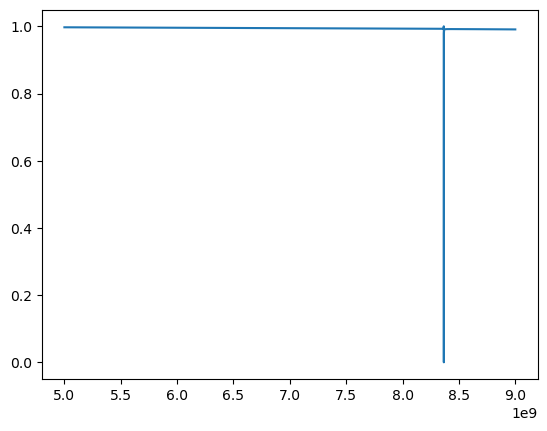

In [4]:
df = pd.read_csv(r".\data\11_04_26_lambda4_res_1800_um_18um_8um_40um.csv",skiprows=1)

freq = 1e9*np.array(df['Frequency (GHz)'])[:1500]
re = np.array(df['RE[S21]'])[:1500]
im = np.array(df['IM[S21]'])[:1500]

s21_sq = re**2+im**2
plt.plot(freq,s21_sq)
results = fit_lorentzian_dip(freq,s21_sq)
print(results['f0']/1e9)
print(results['Q_loaded'])

In [5]:
# Plotting preferences.
plt.rcParams["font.sans-serif"] = ["Arial"] + plt.rcParams["font.sans-serif"]
plt.rcParams["font.family"] = "sans-serif"
%config InlineBackend.figure_format = 'retina'

# Define color scheme: grey to black.
def make_colors(n,name='summer'):
    cmap = cm.get_cmap(name)
    values = np.linspace(0, 1, n)
    colors = cmap(values)
    return colors

In [6]:
"""
Physical constants. 
"""
EPS_R_SAPPHIRE = 9.6 # Sapphire dielectric constant.
EPS_R_hBN = 2.8

In [7]:
# Coplanar capacitance and inductance for center pin of resonator.
def cpw_LC(w,g,sheet_ind):
    # Half in air and half in sapphire.
    eps_eff = 0.5 * (EPS_R_SAPPHIRE + 1)

    # Elliptic modulus.
    k = w / (w + 2*g)
    m = k**2
    m_prime = 1 - m

    # Complete elliptic integrals.
    K_k = ellipk(m)
    K_kprime = ellipk(m_prime)

    # Per-unit-length quantities.
    C_per_length = 4 * epsilon_0 * eps_eff * (K_k / K_kprime)
    L_geom = (mu_0 / 4) * (K_kprime / K_k)
    L_kin = sheet_ind/w
    alpha = L_kin/(L_kin+L_geom)
    L_per_length = (mu_0 / 4) * (K_kprime / K_k) + sheet_ind/w # Plus sheet inductance per unit length.
    z0 = np.sqrt(L_per_length/C_per_length) # Characteristic impedance of resonator.

    print("C':", C_per_length)
    print("L':", L_per_length)
    print('Z0:',z0)

    return C_per_length, L_per_length, z0, alpha

def add_in_series(*Zs):
    return sum(Zs)

def add_in_parallel(*Zs):
    return 1/sum(1/Z for Z in Zs)

def zin_terminated_res(z0,zload,prop_constant):
    zin = z0 * (zload + z0 * np.tanh(prop_constant)) / (z0 + zload * np.tanh(prop_constant))
    return zin

def zin_unloaded_res_lamda2(z0,prop_constant):
    return z0/np.tanh(prop_constant)

def zin_unloaded_res_lamda4(z0,prop_constant):
    return z0*np.tanh(prop_constant)

- Six resonators, 50ohm impedance, vary ground plane gap to increase participation in substrate.
- Gap: 10, 20, 30, 40, 50, 60um.

In [8]:
# (center_pin_width,ground_plane_gap,total_length)
# resonators_params = [(120,14,12000),(112,12,11000),(104,10,10000),(96,8,9000),(88,6,8000)]
resonators_params = [(18,8,10000),(22,16,9750),(26,24,9500),(30,32,9250),(34,40,9000)]

In [12]:
# Transmission line impedance.
sheet_ind = 35e-12 # Starting with 100pH sheet inductance.
center_pin_width = 2e-6
ground_plane_gap = 60e-6
length = 500e-6

feedline_C = 1e-15 # 30fF coupling to feedline.
z_feedline = 50 # Impedance of feedline.

# Find characteristic impedance of resonator based on coplanar waveguide geometry.
C_per_length, L_per_length, z0, alpha = cpw_LC(center_pin_width,ground_plane_gap,sheet_ind)

print("Total L: ", L_per_length*length/1e-9)
print("Total C: ", C_per_length*length/1e-15)

print(alpha)

C': 5.363777438185871e-11
L': 1.8599420206198138e-05
Z0: 588.8630832507185
Total L:  9.299710103099068
Total C:  26.818887190929356
0.9408895441895677


C': 1.145926831679458e-10
L': 1.1028445286748456e-06
Z0: 98.1021899336607


C:\Users\emmag\AppData\Local\Temp\ipykernel_26356\456828447.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap(name)


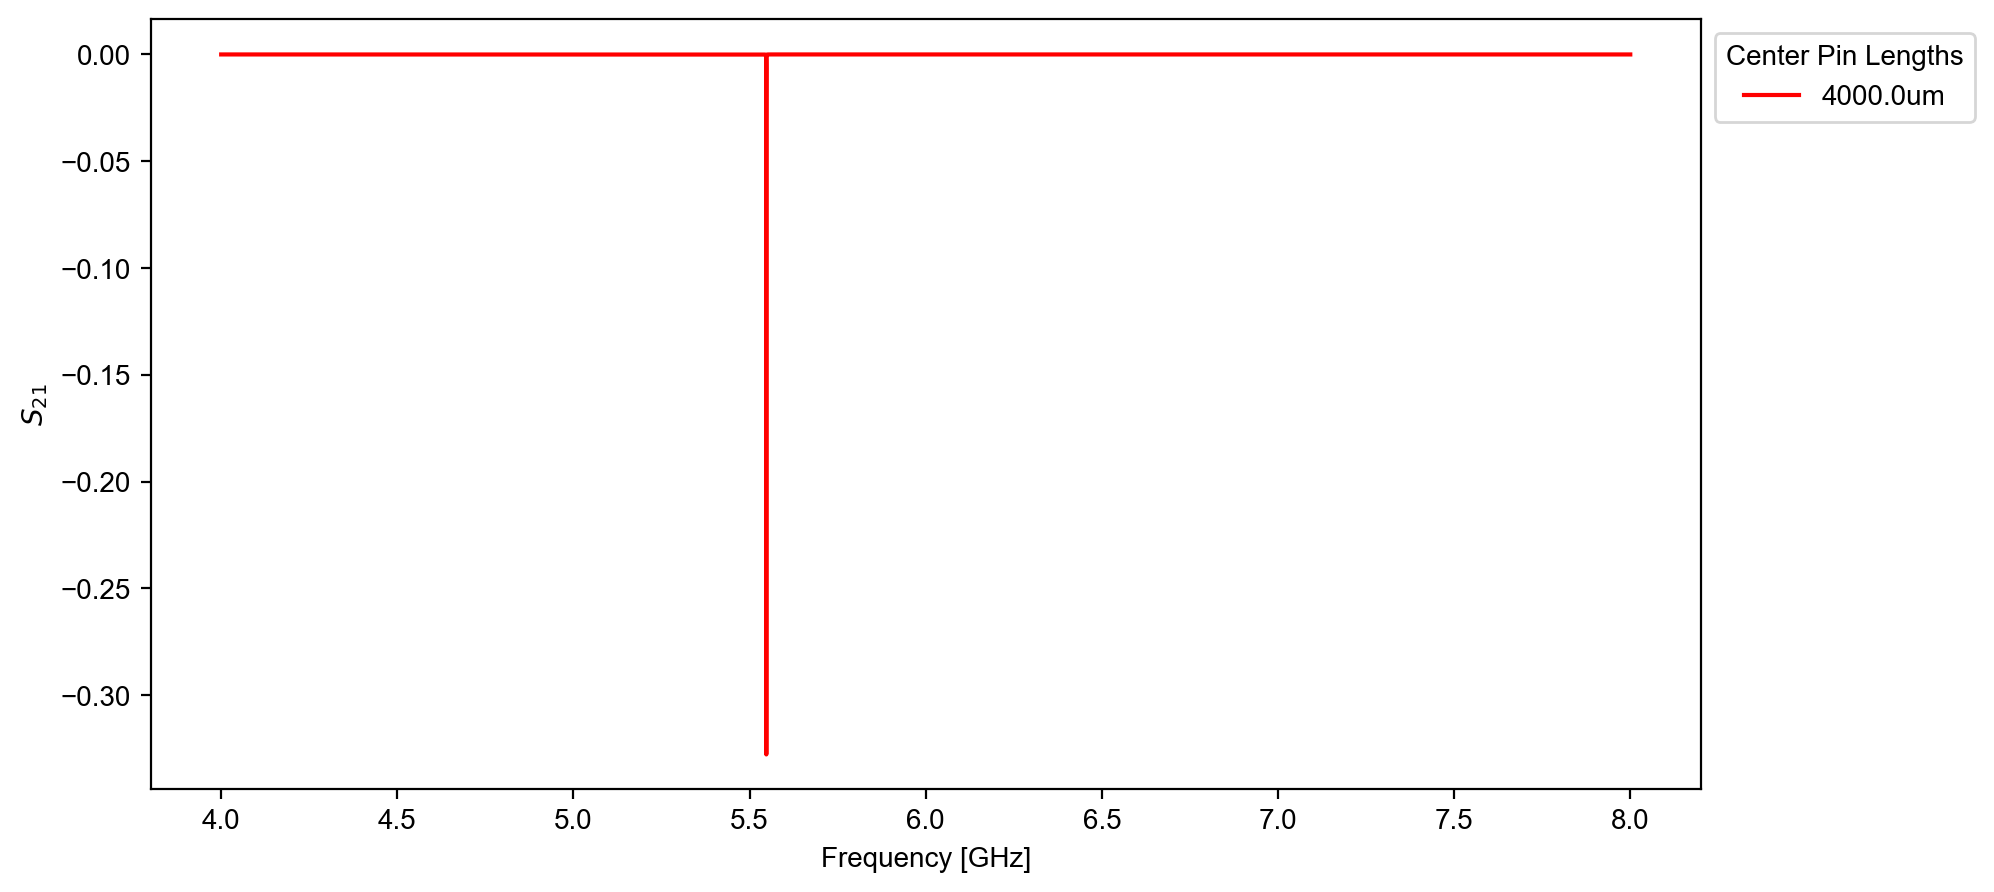

In [16]:
f=np.linspace(4e9,8e9,int(5e4))
sheet_ind = 20e-12 # Starting with 100pH sheet inductance.
center_pin_width = 34e-6
ground_plane_gap = 40e-6
C_per_length, L_per_length, z0, alpha = cpw_LC(center_pin_width,ground_plane_gap,sheet_ind)
plot_resonance(f,center_pin_lengths=[4000e-6],color='red')

In [21]:
l = 16.1e-9
nanowire_width = 1e-6
nanowire_length = 900e-6
nanowire_gap = 100e-6

c =  3.16e-12
cap_width = 800e-6
cap_length = 800e-6
cap_gap = 1e-6

In [22]:
"""
Estimate coupling to feedline as parallel plate capacitance. I think there is also some inductive coupling.
"""
eps_eff = 0.5 * (EPS_R_SAPPHIRE + 1) * epsilon_0

In [14]:
def plot_resonance(f, center_pin_lengths = [12000e-6],color='blue'):
    omegas = 2 * np.pi * f
    colors = make_colors(len(center_pin_lengths))
    for idx in range(len(center_pin_lengths)):
        center_pin_length = center_pin_lengths[idx]
        # color = colors[idx]
        s21_mags = []
        s21_phases = []
        for omega in omegas:

            beta = 1j*omega*np.sqrt(C_per_length*L_per_length)
            prop_constant = beta*center_pin_length

            zin = zin_unloaded_res_lamda4(z0,prop_constant)

            # Solve for impedance presented to transmission line through coupling capacitor.
            coupling_cap = 1/(1j*omega*feedline_C)
            z_coupled = add_in_series(coupling_cap,zin)

            s21 = 2*z_coupled/(2*z_coupled + z_feedline)
            s21_mags.append(10*np.log10(np.abs(s21)**2))
            s21_phases.append(np.angle(s21))

        plt.figure(1,figsize=(10,5))
        plt.plot(f/1e9,s21_mags,label=f'{np.round(center_pin_length*1e6,0)}um',color=color)
        plt.xlabel("Frequency [GHz]")
        plt.ylabel("$S_{21}$")
        plt.legend(title='Center Pin Lengths',bbox_to_anchor=(1,1))

In [21]:
f=np.linspace(1e9,9e9,int(5e4))
sheet_ind = 20e-12 # Starting with 100pH sheet inductance.
center_pin_width = 34e-6
ground_plane_gap = 40e-6
C_per_length, L_per_length, z0 = cpw_LC(center_pin_width,ground_plane_gap,sheet_ind)
plot_resonance(f,center_pin_lengths=[5000e-6],color='red')

C': 1.145926831679458e-10
L': 1.1028445286748456e-06
Z0: 98.1021899336607


NameError: name 'plot_resonance' is not defined